In [1]:
!pip install 'powerlaw'

In [2]:
import bmll2 as b2
from bmll2 import reference, Security, NormalisedSecurity, SparkHelper, get_market_data, get_market_data_range, VenueMarketError, get_market_tables, save_spark_dataframe, load_spark_dataframe

b2.get_file('modules/metaorder.py')
b2.get_file('modules/LMF.py')

import metaorder as metaorder
import LMF as LMF

import random
import math
import pandas as pd
import polars as pl
import numpy as np
from pandas import StringDtype
from datetime import timedelta

import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from matplotlib.ticker import LogFormatterSciNotation

from statsmodels.sandbox.stats.runs import runstest_1samp
import powerlaw
import itertools
import pylab
import scipy.stats
import scipy.fft
from scipy.optimize import curve_fit
from sklearn.model_selection import ParameterGrid

from statsmodels.tsa.stattools import acf
from scipy.stats import t

from typing import Literal

In [3]:
%%time
trader_participation_distribution = 'power'
exchange = 'XJSE'
files = b2.list_files(path = f'data/grid_search_7/{exchange}/{trader_participation_distribution}')

for f in files:
    b2.get_file(f'data/grid_search_7/{exchange}/{trader_participation_distribution}/{f}')

CPU times: user 2.39 s, sys: 104 ms, total: 2.5 s
Wall time: 28.5 s


In [4]:
data = pl.scan_parquet(f'*{trader_participation_distribution}_grid_search.parquet').collect()

if trader_participation_distribution == 'homogenous':
    data.sort(['ticker', 'year', 'N'])
    data.head(10)
if trader_participation_distribution == 'power':
    data.sort(['ticker', 'year', 'N', 'delta'])
    data.head(10)

In [5]:
# estimate = the estimated value
# expected_value = the expectd_value for the point estimate
# var = the variance of the point estimate
# lambda_penalty = the penalty term that the variance should be multiplied by

def error_calculation(estimate, expected_value, var, lambda_penalty = 1):
    error = np.abs(estimate - expected_value) / np.abs(expected_value) 
    ans   = error + lambda_penalty * (var / expected_value ** 2)
    return ans

In [6]:
# returns a dataframe that contains the best configuration for each time scale
# data = dataframe containing the configurations details with estimates for the exponents with variances and interval half widths
# config = do you want the configuration that fits the microscopic/macroscopic values the best. Microscopic refers to the impact curve exponent
# the phi exponent and beta
# estimation_method = wether you want the results for when gamma is estimated using the NLLS or the PSD method
# lambda_penatly = the penalty term for the variance
# mix = how the ratio that individual errors for the impact curve exponent, exponent for phi, and beta should be mixed to get the total macroscopic error

def find_configs(data, trader_participation_distribution, config = Literal['metaorder', 'LMF', 'N', 'combined'],
                   estimation_method = Literal['NLLS', 'PSD'], lambda_penalty = 1, mix = [1, 1, 1]):

    impact_error = error_calculation(data[:, 'impact curve exponent'], 0.5, data[:, 'impact curve exponent var'], lambda_penalty)
    phi_error    = error_calculation(data[:, 'phi exponent'], 0.5, data[:, 'phi exponent var'], lambda_penalty)
    gamma        = data[:, f'gamma ({estimation_method.lower()})']
    beta_error   = error_calculation(data[:, 'beta'], 0.5 * (1 - gamma), data[:, 'beta var'], lambda_penalty)
    alpha_error  = np.abs(data[:, 'alpha'] - 1 - gamma) / (gamma + 1)
    N_error      = np.abs(data[:, 'N (st)'] - data[:, f'N ({estimation_method.lower()})']) / data[:, 'N (st)']

    if trader_participation_distribution == 'homogenous':
        error_df = pl.DataFrame({'year': data.select('year'), 'ticker': data.select('ticker'), 'N': data.select('N'),
                                 f'N_{{ST}}': data.select('N (st)'),
                                 f'N_{{est}}': data.select(f'N ({estimation_method.lower()})'),
                                 #f'$\\delta$': data.select('delta'), 
                                 f'$\\alpha$': data.select('alpha'), 
                                 f'$\\gamma$': data.select(f'gamma ({estimation_method.lower()})'),
                                 
                                 f'\\makecell{{$\\frac{{Q}}{{V_D}}$ \\\\ exponent}}': data.select('impact curve exponent'),
                                 f'\\makecell{{$\\phi$ \\\\ exponent}}': data.select('phi exponent'), 
                                 f'$\\beta$': data.select('beta'), 
                                 f'$\\mathrm{{e}}_{{M}}$ ({estimation_method})': (mix[0] * impact_error + mix[1] * phi_error + mix[2] * beta_error) / sum(mix),
                                 f'$\\mathrm{{e}}_{{LMF}}$ ({estimation_method})': alpha_error,
                                 f'$\\mathrm{{e}}_{{N}}$ ({estimation_method})': N_error,
                                 f'$\\mathrm{{e}}_{{N}}$ ({estimation_method})': (mix[0] * impact_error + mix[1] * phi_error + mix[2] * beta_error) / sum(mix) + alpha_error})
    
    if trader_participation_distribution == 'power':
        error_df = pl.DataFrame({'year': data.select('year'), 'ticker': data.select('ticker'), 'N': data.select('N'),
                                 f'N_{{ST}}': data.select('N (st)'),
                                 f'N_{{est}}': data.select(f'N ({estimation_method.lower()})'),
                                 f'$\\delta$': data.select('delta'), 
                                 f'$\\alpha$': data.select('alpha'), 
                                 f'$\\gamma$': data.select(f'gamma ({estimation_method.lower()})'),
                                 
                                 f'\\makecell{{$\\frac{{Q}}{{V_D}}$ \\\\ exponent}}': data.select('impact curve exponent'),
                                 f'\\makecell{{$\\phi$ \\\\ exponent}}': data.select('phi exponent'), 
                                 f'$\\beta$': data.select('beta'), 
                                 f'$\\mathrm{{e}}_{{M}}$ ({estimation_method})': (mix[0] * impact_error + mix[1] * phi_error + mix[2] * beta_error) / sum(mix),
                                 f'$\\mathrm{{e}}_{{LMF}}$ ({estimation_method})': alpha_error,
                                 f'$\\mathrm{{e}}_{{N}}$ ({estimation_method})': N_error,
                                 f'$\\mathrm{{e}}_{{N}}$ ({estimation_method})': (mix[0] * impact_error + mix[1] * phi_error + mix[2] * beta_error) / sum(mix) + alpha_error})
        
    if (config == 'metaorder'):
        error_df = error_df.sort(f'$\\mathrm{{e}}_{{M}}$ ({estimation_method})').group_by(['ticker', 'year']).first()
        error_df = error_df.sort(['ticker', 'year'])
        return error_df

    if (config == 'LMF'):
        error_df = error_df.sort(f'$\\mathrm{{e}}_{{LMF}}$ ({estimation_method})').group_by(['ticker', 'year']).first()
        error_df = error_df.sort(['ticker', 'year'])
        return error_df

    if (config == 'N'):
        error_df = error_df.sort(f'$\\mathrm{{e}}_{{N}}$ ({estimation_method})').group_by(['ticker', 'year']).first()
        error_df = error_df.sort(['ticker', 'year'])
        return error_df

    if (config == 'combined'):
        error_df = error_df.sort(f'$\\mathrm{{e}}_{{N}}$ ({estimation_method})').group_by(['ticker', 'year']).first()
        error_df = error_df.sort(['ticker', 'year'])
        return error_df
        

In [10]:
b2.get_file('top_250.csv')
top_250 = pd.read_csv('top_250.csv')

top_250_tickers = top_250['Ticker'].tolist()

In [11]:
%%time
files = b2.list_files(path = 'data/trades/top_250')

for f in files:
    b2.get_file(f'data/trades/top_250/{f}')

CPU times: user 9.07 s, sys: 4.56 s, total: 13.6 s
Wall time: 1min 2s


In [12]:
def load_stock(parquet):
    try:
        df = pl.read_parquet(parquet)
        return df.sort(['DateTime', 'ExchangeSequenceNo'])
    except FileNotFoundError:
        return None
        
exchange = 'XJSE'
stocks = {
    ticker: df
    for ticker in top_250_tickers
    if (df := load_stock(f'{ticker}_{exchange}.parquet')) is not None
}

In [15]:
participation_method = 'power'
config               = 'metaorder'
b2.create_folder('data', ensure_exists = True)
b2.create_folder('data/metaorders', ensure_exists = True)
b2.create_folder(f'data/metaorders/{exchange}', ensure_exists = True)
b2.create_folder(f'data/metaorders/{exchange}/calibrated', ensure_exists = True)
b2.create_folder(f'data/metaorders/{exchange}/calibrated/{participation_method}', ensure_exists = True)
b2.create_folder(f'data/metaorders/{exchange}/calibrated/{participation_method}/{config}', ensure_exists = True)

In [ ]:
%%time
trader_participation_distribution = 'power'
group                             = 'year'
config                            = 'LMF'
configs                           = find_configs(data = data, trader_participation_distribution = trader_participation_distribution,
                                                 config = config, estimation_method = 'PSD',
                                                 lambda_penalty = 1, mix = [1, 1, 1])
counter    = 1
start_from = 'BHG'
start      = False
for ticker, stock_data in stocks.items():

    if ticker == start_from:
        start = True

    if not start:
        continue
        
    print(f'{counter}: {ticker}')
    counter += 1

    optimal = configs.filter(pl.col('ticker') == ticker)
    if optimal.is_empty():
        continue

    if trader_participation_distribution == 'homogenous':
        N     = optimal['N'].to_list()
        group = 'year'
        
        if len(N) < 3:
            continue

        stock_features = metaorder.metaorder_data(stock_data, N = N, group = group, trader_participation_distribution = trader_participation_distribution)
        
    if trader_participation_distribution == 'power':
        N     = optimal['N'].to_list()
        delta = optimal[f'$\\delta$'].to_list()
        group = 'year'
        
        if len(N) < 3:
            continue

        stock_features = metaorder.metaorder_data(stock_data, N = N, group = group, trader_participation_distribution = trader_participation_distribution, delta = delta)

    if not stock_features.is_empty():

        stock_features.write_parquet(f'{ticker}_{exchange}_{trader_participation_distribution}_{config}_metaorder_data_calibrated.parquet')
        b2.put_file(f'{ticker}_{exchange}_{trader_participation_distribution}_{config}_metaorder_data_calibrated.parquet',
                    f'data/metaorders/{exchange}/calibrated/{trader_participation_distribution}/{config}')


In [39]:
trader_participation_distribution = 'power'
config = 'LMF'
exchange = 'XJSE'
files = b2.list_files(path = f'data/metaorders/{exchange}/calibrated/{trader_participation_distribution}/{config}')

for f in files:
    b2.get_file(f'data/metaorders/{exchange}/calibrated/{trader_participation_distribution}/{config}/{f}')

In [40]:
all_metaorders = pl.scan_parquet(f'*_XJSE_power_{config}_metaorder_data_calibrated.parquet').collect()

all_metaorders.head(10)

Date,trader id,metaorder id,Ticker,MIC,Start time,End time,Daily Volume,Intraday Volatility,20 AD volume,20 AD volatility,trade sign,volume traded,number child orders,Mid-price before,Mid-price after,Mid-price after (delayed),metaorder impact,metaorder impact (delayed),duration (min)
date,i64,i32,str,str,datetime[μs],datetime[μs],f64,f64,f64,f64,i64,f64,u32,f64,f64,f64,f64,f64,f64
2023-01-20,40,0,"""4SI""","""XJSE""",2023-01-20 10:54:33.694087,2023-01-20 14:02:49.098722,12539.0,0.022008,83473.875,0.018526,-1,11539.0,2,26.0,26.0,26.0,-0.0,-0.0,188.256744
2023-11-28,40,1,"""4SI""","""XJSE""",2023-11-28 13:49:54.996999,2023-11-28 13:49:55.045947,72471.0,0.026497,56931.95,0.027918,-1,59362.0,2,48.0,47.0,46.0,0.021053,0.04256,0.0008158
2023-09-11,40,10,"""4SI""","""XJSE""",2023-09-11 16:12:59.704881,2023-09-11 16:13:00.513940,559870.0,0.016892,346107.65,0.018423,1,74942.0,4,45.0,45.5,48.5,0.01105,0.074901,0.013484
2023-08-17,40,1,"""4SI""","""XJSE""",2023-08-17 15:19:17.747916,2023-08-17 15:42:12.211287,1.573324e6,0.021964,224622.25,0.018221,1,604279.0,5,34.5,35.5,26.0,0.028573,-0.282863,22.907723
2023-03-29,40,1,"""4SI""","""XJSE""",2023-03-29 15:43:45.779277,2023-03-29 16:30:34.667443,54007.0,0.010802,74679.95,0.021755,-1,50000.0,2,26.0,25.0,26.5,0.039221,-0.019048,46.814803
2023-04-03,40,1,"""4SI""","""XJSE""",2023-04-03 09:21:06.864066,2023-04-03 13:55:47.091026,98641.0,0.01488,95151.45,0.020619,1,46247.0,3,24.5,26.0,25.0,0.059423,0.020203,274.670449
2023-09-11,21,0,"""4SI""","""XJSE""",2023-09-11 16:12:59.501218,2023-09-11 16:13:00.025021,559870.0,0.016892,346107.65,0.018423,1,19884.0,2,45.0,45.5,48.5,0.01105,0.074901,0.00873
2023-01-03,40,1,"""4SI""","""XJSE""",2023-01-03 10:46:45.759777,2023-01-03 16:41:13.517232,89288.0,0.0293,89288.0,0.0293,1,22652.0,8,26.0,26.5,43.5,0.019048,0.514664,354.462624
2023-08-14,40,4,"""4SI""","""XJSE""",2023-08-14 15:16:23.439579,2023-08-14 15:16:23.792142,506806.0,0.026995,156062.55,0.018586,1,64000.0,2,38.5,39.0,39.5,0.012903,0.025642,0.005876


In [81]:
ticker   = 'GRT'
exchange = 'XJSE'

b2.get_file(f'data/trades/top_250/{ticker}_{exchange}.parquet')

def load_stock(parquet):
    try:
        df = pl.read_parquet(parquet)
        return df.sort(['DateTime', 'ExchangeSequenceNo'])
    except FileNotFoundError:
        return None

stock = load_stock(f'{ticker}_{exchange}.parquet')

In [82]:
#config            = 'metaorder'
estimation_method = 'PSD'

config_info = find_configs(data = data, trader_participation_distribution = 'power',
                           config = config, estimation_method = estimation_method,
                           lambda_penalty = 1, mix = [1, 1, 1]).filter(pl.col('ticker') == ticker)
config_info

ticker,year,N,N_{ST},N_{est},$\delta$,$\alpha$,$\gamma$,\makecell{$\frac{Q}{V_D}$ \\ exponent},\makecell{$\phi$ \\ exponent},$\beta$,$\mathrm{e}_{M}$ (PSD),$\mathrm{e}_{LMF}$ (PSD),$\mathrm{e}_{N}$ (PSD)
str,i64,i64,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""GRT""",2023,50,50,3.08753,3.0,1.531323,0.482646,0.066946,0.803252,0.191449,0.580126,0.032831,0.612957
"""GRT""",2024,100,100,2.255569,3.0,1.549268,0.433737,0.100366,0.656184,0.119316,0.567025,0.08058,0.647605
"""GRT""",2025,500,44,4.319512,2.0,1.522095,0.489648,0.124153,0.734745,0.129374,0.576365,0.021781,0.598146


In [83]:
print(config_info.to_pandas().to_latex(index = False, float_format = '%.2f'))

\begin{tabular}{lrrrrrrrrrrrrr}
\toprule
ticker & year & N & N_{ST} & N_{est} & $\delta$ & $\alpha$ & $\gamma$ & \makecell{$\frac{Q}{V_D}$ \\ exponent} & \makecell{$\phi$ \\ exponent} & $\beta$ & $\mathrm{e}_{M}$ (PSD) & $\mathrm{e}_{LMF}$ (PSD) & $\mathrm{e}_{N}$ (PSD) \\
\midrule
GRT & 2023 & 50 & 50 & 3.09 & 3.00 & 1.53 & 0.48 & 0.07 & 0.80 & 0.19 & 0.58 & 0.03 & 0.61 \\
GRT & 2024 & 100 & 100 & 2.26 & 3.00 & 1.55 & 0.43 & 0.10 & 0.66 & 0.12 & 0.57 & 0.08 & 0.65 \\
GRT & 2025 & 500 & 44 & 4.32 & 2.00 & 1.52 & 0.49 & 0.12 & 0.73 & 0.13 & 0.58 & 0.02 & 0.60 \\
\bottomrule
\end{tabular}



In [84]:
trader_participation_distribution = 'power'
N                                 = config_info['N'].to_list()
delta                             = config_info[f'$\\delta$'].to_list()
group                             = 'year'

In [85]:
if ticker == 'GRT':
    col = 'olive'
if ticker == 'GFI':
    col = 'purple'

In [86]:
%%time
metaorders = metaorder.metaorder_data(stock, group = group, N = N, trader_participation_distribution = trader_participation_distribution, delta = delta)
executions = metaorder.execution_data(stock, group = group, N = N, trader_participation_distribution = trader_participation_distribution, delta = delta, min_num_child_orders = 3)
decays     = metaorder.decay_data(stock, group = group, N = N, trader_participation_distribution = trader_participation_distribution, delta = delta, min_num_child_orders = 3)

CPU times: user 1min 14s, sys: 8.76 s, total: 1min 23s
Wall time: 52.9 s


In [87]:
b2.create_folder('figures_2', ensure_exists = True)
b2.create_folder('figures_2/time_independence', ensure_exists = True)
b2.create_folder(f'figures_2/time_independence/{exchange}', ensure_exists = True) 
b2.create_folder(f'figures_2/time_independence/{exchange}/calibrated', ensure_exists = True) 
b2.create_folder(f'figures_2/time_independence/{exchange}/calibrated/{config}', ensure_exists = True) 

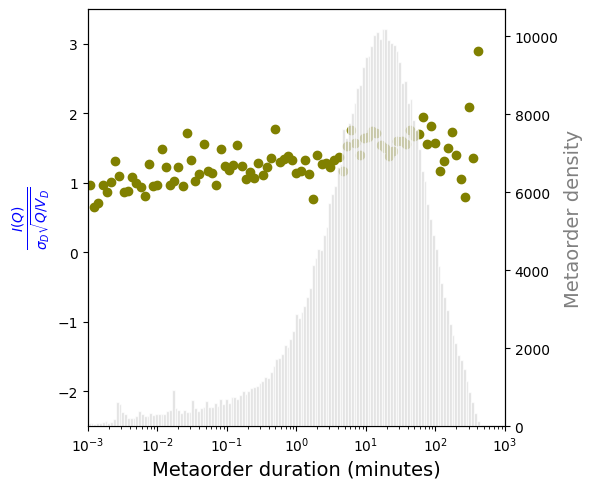

In [88]:
n_intervals = 100

df = metaorders.with_columns(pl.col('duration (min)').alias('x_meta'),
                            (pl.col('metaorder impact') / (pl.col('20 AD volatility') * np.sqrt((pl.col('volume traded') / pl.col('20 AD volume'))))).fill_nan(None).alias('y_meta'))

bins = np.logspace(-3, 3, n_intervals)
df   = df.with_columns([pl.Series('bin', np.digitize(df['x_meta'].to_numpy(), bins) - 1)])

all_bins = pl.DataFrame({'bin': np.arange(len(bins) - 1)})
binned   = df.group_by('bin').agg(pl.col('y_meta').mean().alias('y_mean')).sort('bin')
binned   = all_bins.join(binned, on = 'bin', how = 'left').sort('bin')

bin_centers = (bins[:-1] + bins[1:]) / 2
binned      = binned.with_columns(x_center = bin_centers)

fig, ax1 = plt.subplots(figsize = (6, 6))

ax1.set_xscale('log')
ax1.set_xlim(1e-3, 1e3)
ax1.set_ylim(-2.5, 3.5)

ax1.scatter(binned['x_center'], binned['y_mean'], color = col, marker = 'o')

ax1.set_xlabel('Metaorder duration (minutes)', fontsize = 14)
ax1.set_ylabel(r'$\frac{I(Q)}{\sigma_{D} \sqrt{Q/V_{D}}}$', fontsize = 14, color = 'blue')
ax1.xaxis.set_major_formatter(LogFormatterSciNotation(labelOnlyBase = False))

# Histogram (right axis)
ax2 = ax1.twinx()
bins = np.logspace(-3, 3, 150)
ax2.hist(df['x_meta'], bins = bins, color = 'lightgray', edgecolor = 'white', alpha = 0.7)
ax2.set_ylabel('Metaorder density', fontsize = 14, color = 'gray')

ax1.set_box_aspect(1)
plt.tight_layout()

plt.savefig(f'{ticker}_{exchange}_{config}_calibrated_time_independence.pdf')
b2.put_file(f'{ticker}_{exchange}_{config}_calibrated_time_independence.pdf', f'figures_2/time_independence/{exchange}/calibrated/{config}')
b2.get_file(f'figures_2/time_independence/{exchange}/calibrated/{config}/{ticker}_{exchange}_{config}_calibrated_time_independence.pdf')

plt.show()


In [89]:
b2.create_folder('figures_2', ensure_exists = True)
b2.create_folder('figures_2/impact_curves', ensure_exists = True)
b2.create_folder(f'figures_2/impact_curves/{exchange}', ensure_exists = True) 
b2.create_folder(f'figures_2/impact_curves/{exchange}/calibrated', ensure_exists = True) 
b2.create_folder(f'figures_2/impact_curves/{exchange}/calibrated/{config}', ensure_exists = True) 

Y: 0.032 \pm 0.014
exponent: 0.028 \pm 0.053
GRT & 0.032 $\pm$ 0.014 & 0.028 $\pm$ 0.053


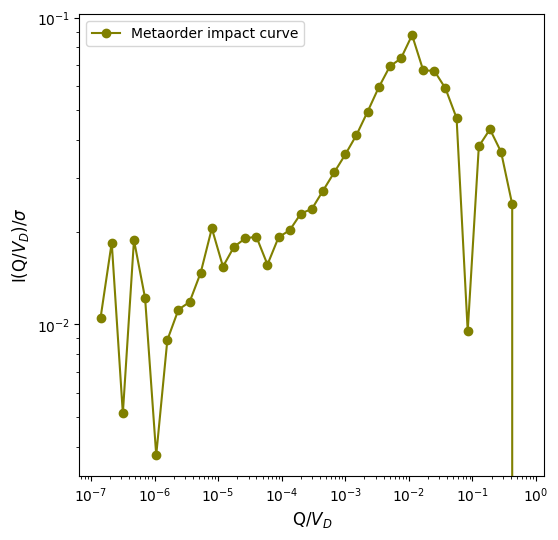

In [90]:
n_intervals = 40

df = metaorders.with_columns((pl.col('volume traded') / pl.col('20 AD volume')).alias('x_meta'),
                            (pl.col('metaorder impact') / pl.col('20 AD volatility')).alias('y_meta'))

x_min = df.select(pl.col('x_meta').min()).item()
x_max = df.select(pl.col('x_meta').max()).item()

bins = np.logspace(np.log10(x_min), np.log10(x_max), n_intervals)
df   = df.with_columns([pl.Series('bin', np.digitize(df['x_meta'].to_numpy(), bins) - 1)])

all_bins = pl.DataFrame({'bin': np.arange(len(bins) - 1)})
binned   = df.group_by('bin').agg(pl.col('y_meta').mean().alias('y_mean')).sort('bin')
binned   = all_bins.join(binned, on = 'bin', how = 'left').sort('bin')

bin_centers = (bins[:-1] + bins[1:]) / 2
binned      = binned.with_columns(x_center = bin_centers)

alpha  = 0.5
binned = binned.with_columns((alpha * pl.col('x_center').sqrt()).alias('sqrt_law'))

def sql_model(x, exp, Y):
    return Y * x ** exp
    
y = np.array(binned['y_mean'])
x = np.array(binned['x_center'])

mask       = (x > 0) & np.isfinite(y)
x_fit      = x[mask]
impact_fit = y[mask]

if len(x_fit) < 10 or len(impact_fit) < 10:
    print('error')
            
try:
    params, covariance = curve_fit(sql_model, x_fit, impact_fit, p0 = [0.5, 0.5], maxfev = 100000)

except RuntimeError:
    print('error')

exp_est = params[0]
Y_est   = params[1]

fitted_curve = sql_model(x, exp_est, Y_est)

n   = len(x_fit)
p   = len(params)          # number of parameters (2 here)
dof = n - p                # degrees of freedom

alpha = 0.05               # 95% CI
tval  = t.ppf(1 - alpha / 2, dof)
se    = np.sqrt(np.diag(covariance))
interval_half_widths = tval * se[0], tval * se[1]

print(f'Y: {Y_est:.3f} \\pm {se[1]:.3f}')
print(f'exponent: {exp_est:.3f} \\pm {se[0]:.3f}')
print(f'{ticker} & {Y_est:.3f} $\\pm$ {se[1]:.3f} & {exp_est:.3f} $\\pm$ {se[0]:.3f}')

fig, ax = plt.subplots(figsize = (6, 6))

ax.set_xscale('log')
ax.set_yscale('log')

#ax.plot(x_bins_centers_meta, y_bins_vals_meta, marker = 'o', color = 'blue', label = 'Metaorder impact curve')
#ax.plot(x_bins_centers_meta, sqrt_law, linestyle = '--', color = 'red', label = r'0.5 $\times \sqrt{Q/V_{D}}$')
ax.plot(binned['x_center'], binned['y_mean'], marker = 'o', color = col, label = 'Metaorder impact curve')
#ax.plot(binned['x_center'], binned['sqrt_law'], linestyle = '--', color = 'red', label = r'0.5 $\times \sqrt{Q/V_{D}}$')

ax.set_xlabel(r'Q/$V_{D}$', fontsize = 12)
ax.set_ylabel(r'I(Q/$V_{D}$)/$\sigma$', fontsize = 12)

ax.xaxis.set_major_formatter(LogFormatterSciNotation(labelOnlyBase = False))
ax.yaxis.set_major_formatter(LogFormatterSciNotation(labelOnlyBase = False))

plt.legend()

plt.savefig(f'{ticker}_{exchange}_{config}_calibrated_impact_curve.pdf')
b2.put_file(f'{ticker}_{exchange}_{config}_calibrated_impact_curve.pdf', f'figures_2/impact_curves/{exchange}/calibrated/{config}')
b2.get_file(f'figures_2/impact_curves/{exchange}/calibrated/{config}/{ticker}_{exchange}_{config}_calibrated_impact_curve.pdf')

plt.show()


In [65]:
b2.create_folder('figures_2', ensure_exists = True)
b2.create_folder('figures_2/concave_profile', ensure_exists = True)
b2.create_folder(f'figures_2/concave_profile/{exchange}', ensure_exists = True) 
b2.create_folder(f'figures_2/concave_profile/{exchange}/calibrated', ensure_exists = True) 
b2.create_folder(f'figures_2/concave_profile/{exchange}/calibrated/{config}', ensure_exists = True) 

Y: 1.192 \pm 0.027
exponent: 0.677 \pm 0.038
GRT & 1.192 $\pm$ 0.027 & 0.677 $\pm$ 0.038


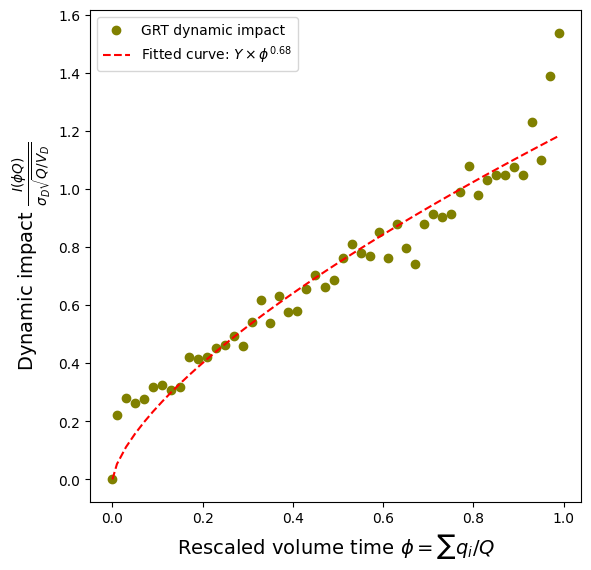

In [91]:
bins = np.linspace(0, 1, 51)
bin_mids = (bins[:-1] + bins[1:]) / 2

df        = executions.with_columns(pl.col('phi').cut(bins).alias('bin'))
binned    = df.group_by('bin').agg(pl.col('dynamical metaorder impact').mean().alias('dynamical metaorder impact (binned)'))
full_bins = pl.DataFrame({'phi': bin_mids}).with_columns(pl.col('phi').cut(bins).alias('bin'))
df        = full_bins.join(binned, on = 'bin', how = 'left').sort('phi')

scaled_impact_binned = df['dynamical metaorder impact (binned)']

if len(scaled_impact_binned) < 10:
    print('error')
    
scaled_impact_binned = pl.concat([pl.Series([0.0]), scaled_impact_binned])
bin_mids             = np.insert(bin_mids, 0, 0)
phi                  = bin_mids

def execution_profile_model(phi, exponent, Y):
    return  Y * (phi ** exponent)

phi    = np.array(phi)
impact = np.array(scaled_impact_binned)

mask       = (phi > 0) & np.isfinite(impact)
phi_fit    = phi[mask]
impact_fit = impact[mask]

if len(phi_fit) < 10 or len(impact_fit) < 10:
    print('error')

try:
    params, covariance = curve_fit(execution_profile_model, phi_fit, impact_fit, p0 = [0.5, 1], maxfev = 100000)

except RuntimeError:
    print('error')
    
phi_est      = params[0]
Y_est        = params[1]

fitted_curve = execution_profile_model(bin_mids, phi_est, Y_est)

n   = len(phi_fit)
p   = len(params)          # number of parameters (2 here)
dof = n - p                # degrees of freedom

alpha = 0.05               # 95% CI
tval  = t.ppf(1 - alpha / 2, dof)
se    = np.sqrt(np.diag(covariance))
interval_half_widths = tval * se[0], tval * se[1]

print(f'Y: {Y_est:.3f} \\pm {se[1]:.3f}')
print(f'exponent: {phi_est:.3f} \\pm {se[0]:.3f}')
print(f'{ticker} & {Y_est:.3f} $\\pm$ {se[1]:.3f} & {phi_est:.3f} $\\pm$ {se[0]:.3f}')

fig, ax = plt.subplots(figsize = (6, 6))

ax.scatter(bin_mids, scaled_impact_binned, color = col, marker = 'o', label = f'{ticker} dynamic impact')
ax.set_xlabel(r'Rescaled volume time $\phi = \sum q_i/Q$', fontsize = 14)
ax.set_ylabel(r'Dynamic impact $\frac{I(\phi Q)}{\sigma_{D} \sqrt{Q/V_{D}}}$', fontsize = 14)
ax.plot(bin_mids, fitted_curve, color = 'red', linestyle = '--', label = rf'Fitted curve: $Y \times\phi^{{{phi_est:.2f}}}$')
ax.set_yscale('linear')
ax.legend()

ax.set_box_aspect(1)
plt.tight_layout()

plt.savefig(f'{ticker}_{exchange}_{config}_calibrated_concave_profile.pdf')
b2.put_file(f'{ticker}_{exchange}_{config}_calibrated_concave_profile.pdf', f'figures_2/concave_profile/{exchange}/calibrated/{config}')
b2.get_file(f'figures_2/concave_profile/{exchange}/calibrated/{config}/{ticker}_{exchange}_{config}_calibrated_concave_profile.pdf')

plt.show()


In [92]:
b2.create_folder('figures_2', ensure_exists = True)
b2.create_folder('figures_2/impact_decay', ensure_exists = True)
b2.create_folder(f'figures_2/impact_decay/{exchange}', ensure_exists = True) 
b2.create_folder(f'figures_2/impact_decay/{exchange}/calibrated', ensure_exists = True)
b2.create_folder(f'figures_2/impact_decay/{exchange}/calibrated/{config}', ensure_exists = True)

Y: 2.012 \pm 0.004
exponent: 0.167 \pm 0.002
GRT & 2.012 $\pm$ 0.004 & 0.167 $\pm$ 0.002


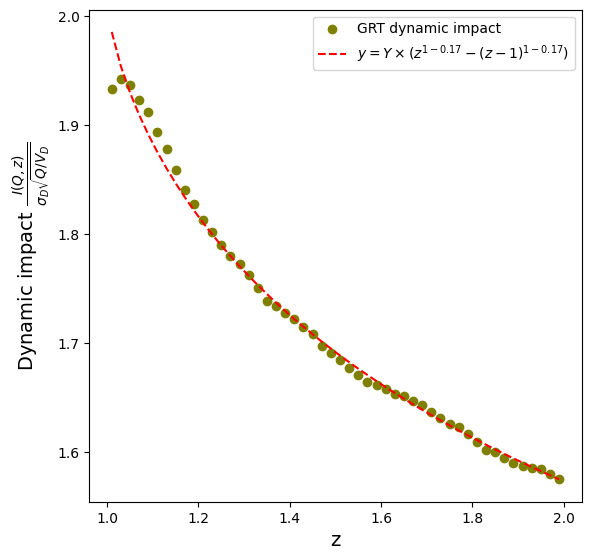

In [93]:
bins = np.linspace(1, 2, 51)
bin_mids = (bins[:-1] + bins[1:]) / 2

df        = decays.with_columns(pl.col('z').cut(bins).alias('bin'))
binned    = df.group_by('bin').agg(pl.col('dynamical metaorder impact').mean().alias('dynamical metaorder impact (binned)')).sort('bin')
full_bins = pl.DataFrame({'z': bin_mids}).with_columns(pl.col('z').cut(bins).alias('bin'))
df        = full_bins.join(binned, on = 'bin', how = 'left').sort('z')

z         = np.array(bin_mids)
impact    = np.array(df['dynamical metaorder impact (binned)'])

def decay_model(z, beta, Y):
    return  Y * (z ** (1 - beta) - (z - 1) ** (1 - beta))

mask       = (z > 1) & np.isfinite(impact)
z_fit      = z[mask]
impact_fit = impact[mask]

if len(z_fit) < 10 or len(impact_fit) < 10:
    print('error')

try:
    params, covariance = curve_fit(decay_model, z_fit, impact_fit, p0 = [0.2, 1], maxfev = 100000)

except RuntimeError:
    print('error')  

beta_est = params[0]
Y_est    = params[1]

fitted_curve = decay_model(z_fit, beta_est, Y_est)

n   = len(z_fit)
p   = len(params)          # number of parameters (2 here)
dof = n - p                # degrees of freedom

alpha = 0.05               # 95% CI
tval  = t.ppf(1 - alpha / 2, dof)
se    = np.sqrt(np.diag(covariance))
interval_half_widths = tval * se[0], tval * se[1]

print(f'Y: {Y_est:.3f} \\pm {se[1]:.3f}')
print(f'exponent: {beta_est:.3f} \\pm {se[0]:.3f}')
print(f'{ticker} & {Y_est:.3f} $\\pm$ {se[1]:.3f} & {beta_est:.3f} $\\pm$ {se[0]:.3f}')


fig, ax = plt.subplots(figsize = (6, 6))

ax.scatter(bin_mids, df['dynamical metaorder impact (binned)'], color = col, marker = 'o', label = f'{ticker} dynamic impact')
ax.plot(z_fit, fitted_curve, color = 'red', linestyle = '--',
        label = rf'$y = Y\times\left(z^{{1-{beta_est:.2f}}} - \left(z-1\right)^{{1-{beta_est:.2f}}}\right)$')
ax.set_xlabel(r'z', fontsize = 14)
ax.set_ylabel(r'Dynamic impact $\frac{I(Q, z)}{\sigma_{D} \sqrt{Q/V_D}}$', fontsize = 14)
ax.legend()

ax.set_box_aspect(1)
plt.tight_layout()

plt.savefig(f'{ticker}_{exchange}_{config}_calibrated_impact_decay.pdf')
b2.put_file(f'{ticker}_{exchange}_{config}_calibrated_impact_decay.pdf', f'figures_2/impact_decay/{exchange}/calibrated/{config}')
b2.get_file(f'figures_2/impact_decay/{exchange}/calibrated/{config}/{ticker}_{exchange}_{config}_calibrated_impact_decay.pdf')

plt.show()

In [111]:
#config = 'metaorder'
estimation_method = 'PSD'

configs = find_configs(data = data, trader_participation_distribution = 'power',
                           config = config, estimation_method = estimation_method,
                           lambda_penalty = 1, mix = [1, 1, 1])#.filter(pl.col('ticker') == 'GRT')

alpha_estimate = configs[f'$\\alpha$'] - 1
gamma_estimate = configs[f'$\\gamma$']

In [112]:
b2.create_folder('figures_2', ensure_exists = True)
b2.create_folder('figures_2/alpha_gamma', ensure_exists = True)
b2.create_folder(f'figures_2/alpha_gamma/{exchange}', ensure_exists = True)
b2.create_folder(f'figures_2/alpha_gamma/{exchange}/calibrated', ensure_exists = True)
b2.create_folder(f'figures_2/alpha_gamma/{exchange}/calibrated/{config}', ensure_exists = True)

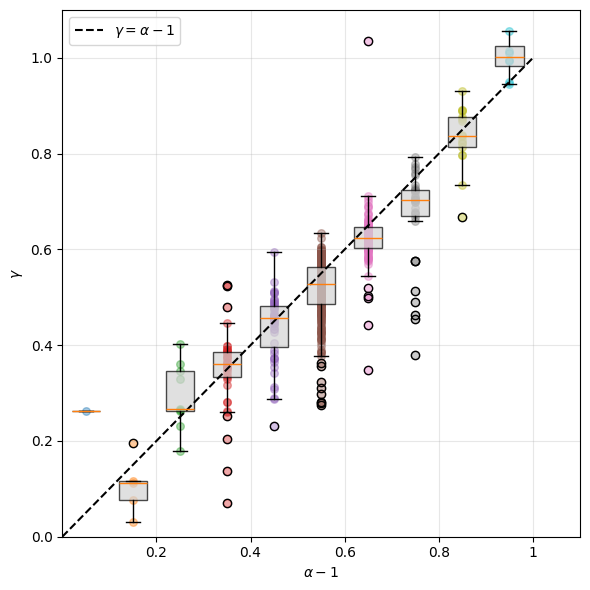

In [96]:
df = pl.DataFrame({'alpha - 1': alpha_estimate, 'gamma': gamma_estimate})

bins = np.linspace(0, 1, 11)

df = df.with_columns(pl.col('alpha - 1').cut(bins).alias('bin'))

bin_mids = (bins[:-1] + bins[1:]) / 2


plt.figure(figsize = (6, 6))

for i in range(len(bin_mids)):
    
    lower = bins[i]
    upper = bins[i+1]

    gamma_vals = df.filter((pl.col('alpha - 1') >= lower) &(pl.col('alpha - 1') < upper)).select('gamma').drop_nulls().to_series().to_numpy()
    
    if len(gamma_vals) == 0:
        continue

    # Boxplot at midpoint
    plt.boxplot(gamma_vals, positions = [bin_mids[i]], widths = 0.06, patch_artist = True, showfliers = True,
                boxprops = dict(facecolor = 'lightgray', alpha = 0.7)) #showmeans = True, meanline = True

    # Scatter points
    plt.scatter(np.full(len(gamma_vals), bin_mids[i]), gamma_vals, alpha = 0.4, s = 30)

# Theoretical line
plt.plot([0, 1], [0, 1], 'k--', label = r'$\gamma = \alpha - 1$')

plt.xticks(ticks = [0.2, 0.4, 0.6, 0.8, 1.0], labels = ['0.2', '0.4', '0.6', '0.8', '1'])
plt.xlabel(r'$\alpha - 1$')
plt.ylabel(r'$\gamma$')
plt.xlim(0, 1.1)
plt.ylim(0, 1.1)
plt.grid(alpha = 0.3)
plt.legend()
plt.tight_layout()

plt.savefig(f'{config}_calibrated_alpha_gamma_{estimation_method}.pdf')
b2.put_file(f'{config}_calibrated_alpha_gamma_{estimation_method}.pdf', f'figures_2/alpha_gamma/{exchange}/calibrated/{config}')
b2.get_file(f'figures_2/alpha_gamma/{exchange}/calibrated/{config}/{config}_calibrated_alpha_gamma_{estimation_method}.pdf')

plt.show()
